<a href="https://colab.research.google.com/github/ashsiendo/DATA-201-Labs/blob/main/Assignments/Week9_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Week 9 Homework** - Ash Ibasan

Let's use the `Carseats` dataset from week 9's lab to build a classification decision tree that predicts if a store has high or low sales.

We'll pick the best tree depth on the basis of the cross-validation, assess the final model on the test set, and then interpret the results. We'll begin with a tree of `max_depth=3`, and then various tree depths (again using 5-fold CV) will be evaluated to see how tree complexity impacts accuracy and overfitting.

> **Note to self: Comments throughout are used as guides, mainly for Python syntax, reasons why certain steps are used, and understanding and interpreting the results.**

## Setup - Imports

In [6]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [7]:
# import relevant libraries
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data # for part 1
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

## Part 1 - Build a Classification Tree

In part 1, let's prep the `Carseats` data and split it 70/30 (70% training, 30% testing), then go and train a classification tree with a max depth of 3. We'll then visualize the tree and check its accuracy on both the training and test sets to see how well it performs


### 1.1 Load, prepare data

In [8]:
carseats = load_data('Carseats') # load Carseats dataset
carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [9]:
# create binary target variable: High Sales = 1, Low Sales = 0
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales']) # remove Sales - it was used to create target

# check the number of stores in each category
print(carseats['HighSales'].value_counts())


HighSales
0    236
1    164
Name: count, dtype: int64


***Note to self:***
`HighSales` is a binary target variable, so we're in the classification space rather than the regression space. We're predicting if a store has high or low sales rather than predicting the actual amount of sales here.

> `(carseats['Sales'] > 8)` returns True or False, and `.astype(int)` turns those into `1` (High Sales) and `0` (Low Sales)

> We drop `Sales` as a variable because `HighSales` was created directly from `Sales`. We’d have target leakage if we were to keep `Sales` as a predictor as the model would have access to the information that was used to determine the target


### 1.2 Encode categorical predictors

In [10]:
# define predictors (X) and target variable (y)
X = carseats.drop(columns='HighSales')
y = carseats['HighSales']

# one-hot encode categorical predictors
X = pd.get_dummies(
    X,
    columns=['ShelveLoc', 'Urban', 'US'],
    dtype=int
)
X.head()

,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium,Urban_No,Urban_Yes,US_No,US_Yes
0,138,73,11,276,120,42,17,1,0,0,0,1,0,1
1,111,48,16,260,83,65,10,0,1,0,0,1,0,1
2,113,35,10,269,80,59,12,0,0,1,0,1,0,1
3,117,100,4,466,97,55,14,0,0,1,0,1,0,1
4,141,64,3,340,128,38,13,1,0,0,0,1,1,0


***Note to self:*** `pd.get_dummies()` applies one-hot encoding, turning categorical predictors into separate columns the decision tree could use.

> `X` contains the predictors and y contains our target variable (`HighSales`)

> `ShelveLoc`, `Urban`, and `US` are categorical predictors, so we've encoded them into numerical columns

> `dtype=int` saves the encoded columns as integers (`0` and `1`) rather than as Boolean values (`True` and `False`)


### 1.3 Training/test split

In [11]:
# split data - 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)
print(X_train.shape, X_test.shape) # check training, test sizes

(280, 14) (120, 14)


***Note to self:*** Remember, the data is split 70% training, 30% testing - we can train the model on one set and evaluate its performance on unseen data.

> `test_size=0.30` sets 30% of the data aside to test

> `random_state=42` makes split reproducible (the same every time)

> `stratify=y` keeps the ratio of high- and low-sales stores about the same in both sets

### 1.4 Train and plot classification tree

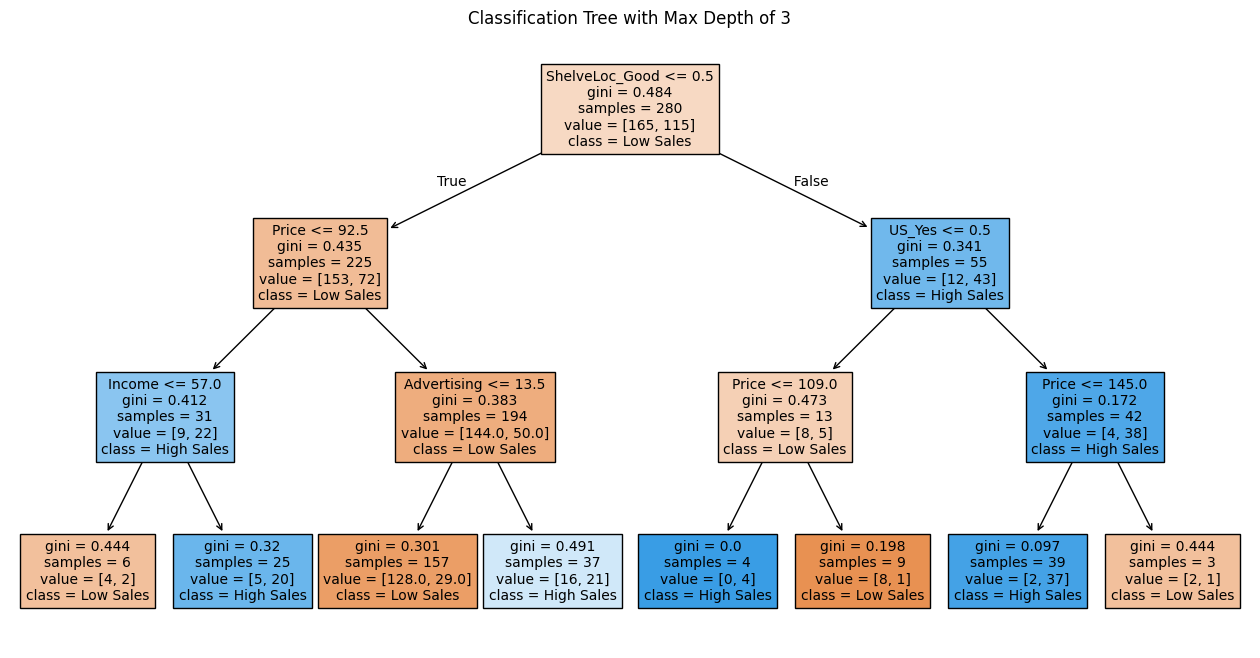

The TRAIN accuracy is 0.8
The TEST accuracy is 0.8


In [12]:
# fit classification tree - max depth of 3
tree3 = DecisionTreeClassifier(max_depth=3, random_state=42)
tree3.fit(X_train, y_train)

# visualize the classification tree
plt.figure(figsize=(16, 8))

plot_tree(
    tree3,
    feature_names=list(X.columns),
    class_names=['Low Sales', 'High Sales'],
    filled=True,
    fontsize=10
)

plt.title('Classification Tree with Max Depth of 3')
plt.show()

# compare training, test accuracy
print('The TRAIN accuracy is', round(tree3.score(X_train, y_train), 3))
print('The TEST accuracy is', round(tree3.score(X_test, y_test), 3))


***Note to self:*** `max_depth=3` limits the tree to ***three*** levels of splits below the root node (limits the complexity of the tree and hence reduces the risk of over-fitting).

> `.fit()` trains the decision tree with the training data

> `plot_tree()` draws the tree and shows the split conditions, Gini impurity, number of samples at each node, and the predicted class

> ***Gini impurity*** shows how mixed the classes are in a node. A lower value means the samples are mostly from one class

> `.score()` gives the accuracy rate, which is the proportion of correctly classified samples

**Results**

The classification tree with `max_depth=3` achieved 80% accuracy on both the training and test sets. The accuracy is the same on both sets, so there's no obvious sign of overfitting at that depth.

However, it doesn't necessarily mean that depth 3 is the best option. We'll be comparing the various tree depths in the next part using CV to see which one comes out on top.

## Part 2 - Investigate Overfitting
Decision trees with `max_depth` values from `1` to `10` will be assessed using 5-fold CV on the training data, and we'll plot the average accuracy for each depth to see how performance changes as the trees get more complex and to look for any signs of overfitting.

Next, we'll pick the depth that does best in the CV and then test the final tree on the test set.


### 2.1 Compare tree depths using 5-fold CV

In [13]:
# compare tree depths from 1 to 10 using 5-fold cross-validation
depths = range(1, 11)
cv_accuracy = []

for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    cv_accuracy.append(scores.mean())

    print(f"Depth {d} has a mean CV accuracy of {scores.mean():.3f}")

Depth 1 has a mean CV accuracy of 0.668
Depth 2 has a mean CV accuracy of 0.682
Depth 3 has a mean CV accuracy of 0.711
Depth 4 has a mean CV accuracy of 0.729
Depth 5 has a mean CV accuracy of 0.693
Depth 6 has a mean CV accuracy of 0.732
Depth 7 has a mean CV accuracy of 0.714
Depth 8 has a mean CV accuracy of 0.729
Depth 9 has a mean CV accuracy of 0.721
Depth 10 has a mean CV accuracy of 0.718


***Note to self:*** `max_depth` is a hyperparameter that caps the depth of the tree. We're going to try out values from 1 to 10 and see which one is best, again, using more than a single train/test split.

> `range(1, 11)` gives us the tree depths from 1 to 10, and `cv_accuracy = []` is where we'll store the average CV scores for each depth

> The loop '`for d in depths`' trains and tests a tree with each depth in turn

> `cross_val_score()` does 5-fold CV on the training data. Each time, it trains on four parts and tests on the 5th one, and it does this five times

> `scores.mean()` gives us the mean accuracy across the five folds, which we store in `cv_accuracy` to compare the different depths

We use the training data for CV so that the test set stays separate until we get to the point of evaluating the final model.

### 2.2 Graph tree depth versus CV accuracy

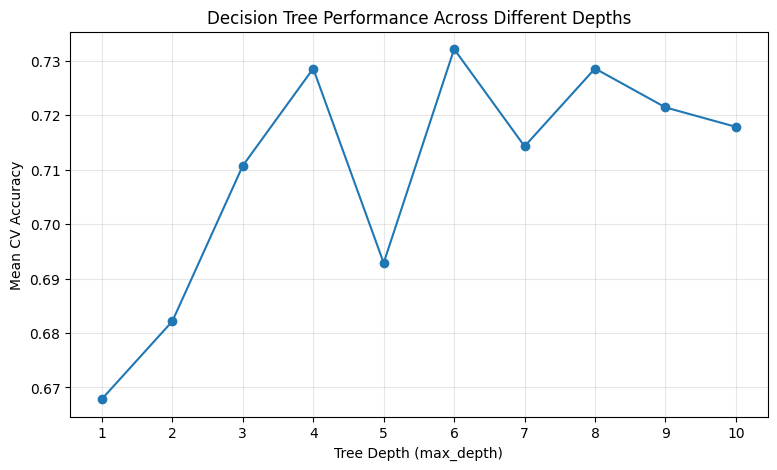

In [14]:
plt.figure(figsize=(9, 5)) # plot tree depth against mean cv accuracy
plt.plot(depths, cv_accuracy, marker='o')

plt.xlabel('Tree Depth (max_depth)')
plt.ylabel('Mean CV Accuracy')
plt.title('Decision Tree Performance Across Different Depths') # or cv accuracy by tree depths
plt.xticks(list(depths))
plt.grid(alpha=0.3)
plt.show()

### 2.3 Identify the best depth

In [15]:
# select depth with highest mean CV accuracy
best_depth = depths[cv_accuracy.index(max(cv_accuracy))]

print('Best max depth:', best_depth)
print('Best mean CV accuracy:', round(max(cv_accuracy), 3))

Best max depth: 6
Best mean CV accuracy: 0.732


***Note to self:*** We're going with the tree depth that has the highest mean CV accuracy from section 2.1.

> `max(cv_accuracy)` gives us the max mean CV accuracy

> `.index()` tells us where that accuracy is in the list

> `depths[...]` uses that position to find the matching tree depth

If more than one depth has the highest accuracy, `.index()` will pick the first one it finds, the smallest depth in our list.

### 2.4 Train and evaluate final tree

In [ ]:
# train final classification tree using the best depth
final_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
final_tree.fit(X_train, y_train)

# evaluate the final tree on the test set
print('The final tree depth is', best_depth)
print('The final test accuracy is', round(final_tree.score(X_test, y_test), 3))

Final tree depth: 6
Final test accuracy: 0.733


***Note to self:*** We train our final classification tree using the best depth chosen by CV.

> We set the max depth (`max_depth=best_depth`) to the value chosen in section 2.3 (depth 6)

> We train the final tree on the full training set using `.fit(X_train, y_train)` rather than fitting a separate tree for each validation fold

> We use `.score(X_test, y_test)` to see how well the model we've selected performs on the new test data

The test set is purely for the final evaluation; tree depth won’t be chosen at this stage.

**Results**

The CV graph shows accuracy increasing from depth 1 to depth 4, then fluctuating as the tree gets deeper. Depth 6 gave the highest average CV accuracy (73.2%), so that's the one we've gone with for our final classification tree.

The final tree at max depth of 6, with 73.3% accuracy on the test set, is very close to its average CV accuracy, and increasing the depth did not always improve results, so a more complex tree does not always work better on new data.

## Part 3 - Questions

**Interpreting the tree**

*Which predictor was selected for the first split (root)? What does this split tell us about sales?*

The first split is on `ShelveLoc_Good <= 0.5` (good shelf location versus not). 43 of the 55 stores with a good shelf location had high sales (78.2%), while only 72 out of 225 stores without a good shelf location had high sales (32%) in the training set, and it shows stores with a good shelf location tend to have higher sales. That’s why the tree picked this variable first- it best separated stores with high sales from those with low sales.


**Choosing tree depth**

*According to your CV graph, which depth performed best? Why should we use CV rather than test accuracy to choose the depth?*

> A tree with a depth of 6 gave the best results, with an average CV accuracy of 73.2%- depth 6 was picked since it had the highest average accuracy across the five validation folds.

> We use CV on the training data to compare different tree depths rather than use test accuracy, so we can assess performance across the folds and keeps the test set separate for the final evaluation. If we used test accuracy to pick the depth, the test data would influence our choice, making the final evaluation invalid.


**Overfitting**

*Does increasing tree depth always improve CV accuracy? Explain using your graph.*

> Making the tree deeper does not always improve CV accuracy. The graph shows 66.8% at depth 1, going up to 72.9% at depth 4, then dropping to 69.3% at depth 5. It reaches 73.2% at depth 6, and changes again at deeper levels- it's quite clear that making the tree deeper doesn't necessarily result in better performance on new data. Also, a deeper tree can also start to fit the noise in the training data, increasing overfitting risk.